# 01. Знакомство с данными

**Цель.** Понять, что за данные у меня есть, можно ли им доверять и подходят ли они для задачи "предсказать, купит ли посетитель". В конце ноутбука я один раз делю данные на обучающую и тестовую части. Все следующие ноутбуки работают только с обучающей частью, а тест я открою один раз, в конце моделирования.

**Что уже известно.** Это первый шаг, поэтому пока известна только постановка задачи: по поведению посетителя за одну сессию понять, что влияет на покупку, и научиться её предсказывать.

*Сессия* означает один визит на сайт: человек зашёл, посмотрел несколько страниц и ушёл (купив что-то или нет).

## Откуда данные

Я взял датасет **Online Shoppers Purchasing Intention** из репозитория UCI (Sakar & Kastro, 2018, лицензия CC BY 4.0, DOI [10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q)). Его авторы опубликовали статью о предсказании покупки в реальном времени: Sakar et al., *Neural Computing and Applications*, 2019.

Что важно знать о данных по описанию авторов:
- одна строка соответствует одной сессии в интернет-магазине, всего данные за год;
- **каждая сессия принадлежит отдельному пользователю**. Авторы сделали так специально, чтобы данные не перекосило в сторону одной рекламной кампании или одного типа клиентов. Для меня это значит, что один и тот же человек не попадёт одновременно в обучение и в тест;
- признаки собраны из Google Analytics (GA). Это система, которая записывает, какие страницы смотрит посетитель и сколько на них проводит.

## Почему я выбрал этот датасет и чего в нём нет

Подходит, потому что: данные на уровне сессии, есть целевая переменная "была покупка или нет" (`Revenue`), есть поведенческие признаки (сколько страниц и сколько времени), есть тип посетителя (новый / вернувшийся). Датасет маленький (около 1 МБ), поэтому эксперименты идут быстро.

Чего нет и как это ограничивает выводы:

| Чего нет | Что из-за этого придётся делать |
|---|---|
| Сумм заказов, цен, маржи | Прибыль в бизнес-симуляции (ноутбук 07) считаю на допущениях и проверяю, насколько вывод чувствителен к ним |
| Событий "положил в корзину" | "Брошенную корзину" напрямую увидеть нельзя. Сегмент "почти-покупателей" (ноутбук 06) придётся определять по поведению и по оценке модели |
| Порядка действий внутри сессии | Все признаки посчитаны по сессии целиком. Модель знает, что было за весь визит, а в реальности решение о промокоде принимается раньше. Значит, на практике она будет работать хуже, чем на этих данных |
| ID пользователя и контактов | Нельзя проследить человека между визитами и отправить ему письмо |
| Расшифровки кодов ОС, браузера, региона, источника трафика | Могу сказать "источник 2 конвертирует лучше", но не "реклама в поиске работает лучше" |
| Точных дат (есть только месяц) | Нельзя честно проверить модель "на будущем": разбиение только случайное |

## Загрузка

In [1]:
import sys
from pathlib import Path

# Чтобы импортировать модули из src/, добавляю корень проекта в путь
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import RAW_PATH, TARGET
from src.data import clean, load_raw, make_split, save_split
from src.plots import BLUE, CLASS_COLORS, CLASS_LABELS, save_fig, setup_style

setup_style()
pd.set_option("display.max_columns", 30)

raw = load_raw()
print(f"Файл {RAW_PATH.name}: {raw.shape[0]} строк, {raw.shape[1]} колонок")
raw.head()

Файл online_shoppers_intention.csv: 12330 строк, 18 колонок


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## Что означает каждая колонка

Ниже таблица с тремя столбцами: колонка, что она означает простыми словами и пример значения. Пример я взял из первой сессии в файле, которая закончилась покупкой: в ней большинство значений ненулевые, и по ним легче понять смысл колонок.

Термины из Google Analytics, которые встречаются в таблице:
- **показатель отказов (bounce rate)** страницы: какая доля людей, начавших визит с этой страницы, ушла, ничего больше не открыв;
- **показатель выхода (exit rate)** страницы: какая доля просмотров этой страницы оказалась последней в визите;
- **ценность страницы (page value)**: сколько выручки в среднем "приходится" на просмотр страницы, если её смотрели перед покупкой.

Эти три показателя считаются для каждой страницы сайта по всем посетителям. В датасете для сессии записано их среднее по страницам, которые посмотрел этот посетитель.

In [2]:
descriptions = {
    "Administrative": "Сколько служебных страниц посмотрел (например, личный кабинет; точный список авторы не приводят)",
    "Administrative_Duration": "Сколько секунд провёл на служебных страницах",
    "Informational": "Сколько информационных страниц посмотрел (о магазине, доставке, контактах)",
    "Informational_Duration": "Сколько секунд провёл на информационных страницах",
    "ProductRelated": "Сколько страниц, связанных с товарами, посмотрел (карточки, каталог)",
    "ProductRelated_Duration": "Сколько секунд провёл на товарных страницах",
    "BounceRates": "Средний показатель отказов страниц, которые он посмотрел",
    "ExitRates": "Средний показатель выхода страниц, которые он посмотрел",
    "PageValues": "Средняя ценность посмотренных страниц из GA (связана с выручкой, разбираю в 04)",
    "SpecialDay": "Близость к празднику (14 февраля, День матери): от 0 до 1, где 1 означает пиковый день перед праздником",
    "Month": "Месяц визита",
    "OperatingSystems": "Код операционной системы (без расшифровки)",
    "Browser": "Код браузера (без расшифровки)",
    "Region": "Код региона (без расшифровки)",
    "TrafficType": "Код источника трафика: откуда пришёл посетитель (без расшифровки)",
    "VisitorType": "Тип посетителя: новый, вернувшийся или другое",
    "Weekend": "Был ли визит в выходной",
    "Revenue": "Была ли покупка. Это и есть то, что я предсказываю (целевая переменная)",
}
example = raw[raw[TARGET]].iloc[0]
columns_table = pd.DataFrame({
    "что означает": pd.Series(descriptions),
    "пример значения": example.astype(str),
    "тип в pandas": raw.dtypes.astype(str),
})
columns_table

,что означает,пример значения,тип в pandas
Administrative,"Сколько служебных страниц посмотрел (например,...",3,int64
Administrative_Duration,Сколько секунд провёл на служебных страницах,87.83333333,float64
Informational,Сколько информационных страниц посмотрел (о ма...,0,int64
Informational_Duration,Сколько секунд провёл на информационных страницах,0.0,float64
ProductRelated,"Сколько страниц, связанных с товарами, посмотр...",27,int64
ProductRelated_Duration,Сколько секунд провёл на товарных страницах,798.3333333,float64
BounceRates,"Средний показатель отказов страниц, которые он...",0.0,float64
ExitRates,"Средний показатель выхода страниц, которые он ...",0.012643678,float64
PageValues,Средняя ценность посмотренных страниц из GA (с...,22.9160357,float64
SpecialDay,"Близость к празднику (14 февраля, День матери)...",0.8,float64


**Что увидел.** 18 колонок: 10 числовых признаков поведения, 7 категориальных признаков и целевая переменная `Revenue`. Четыре категориальных признака (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) записаны числами, но это коды: "браузер 4" не "больше" "браузера 2". Модели нужно будет объяснить, что это категории.

**Что это значит.** Набор признаков бедный: только количество страниц трёх типов, время на них и три метрики GA. Нет ни товаров, ни цен, ни корзины. Всё, что я узнаю о поведении, я узнаю из этих 10 чисел.

## Пропуски, типы, странные значения

**Что хочу проверить.** Есть ли пропуски, отрицательные значения времени и сессии, которые выглядят нелогично (например, ноль страниц).

In [3]:
numeric_cols = raw.select_dtypes("number").columns
total_pages = raw[["Administrative", "Informational", "ProductRelated"]].sum(axis=1)
total_duration = raw[["Administrative_Duration", "Informational_Duration",
                      "ProductRelated_Duration"]].sum(axis=1)

checks = pd.Series({
    "пропусков во всей таблице": raw.isna().sum().sum(),
    "отрицательных значений в числовых колонках": (raw[numeric_cols] < 0).sum().sum(),
    "сессий с нулём страниц": (total_pages == 0).sum(),
    "сессий с одной страницей": (total_pages == 1).sum(),
    "  из них с нулевой длительностью": ((total_pages == 1) & (total_duration == 0)).sum(),
    "сессий с нулевой общей длительностью": (total_duration == 0).sum(),
    "  из них, где страниц больше одной": ((total_duration == 0) & (total_pages > 1)).sum(),
})
checks.to_frame("число")

,число
пропусков во всей таблице,0
отрицательных значений в числовых колонках,0
сессий с нулём страниц,6
сессий с одной страницей,597
из них с нулевой длительностью,546
сессий с нулевой общей длительностью,720
"из них, где страниц больше одной",168


**Что увидел.** Пропусков и отрицательных значений нет. Есть 6 сессий с нулём страниц и 720 сессий с нулевой длительностью. Из 597 сессий с одной страницей у 546 время равно нулю.

**Что это значит.** Скорее всего, это особенность того, как Google Analytics считает время: время на странице равно промежутку между открытием этой страницы и открытием следующей. У последней страницы визита "следующей" нет, поэтому её время не записывается. Отсюда два следствия:
1. визит из одной страницы почти всегда длится "0 секунд", даже если человек читал её минуту;
2. в любой сессии время на последней странице потеряно, то есть длительности занижены, и сильнее всего у коротких визитов.

Удалять такие сессии я не буду: это реальные визиты, и модель в работе будет видеть такие же. Но при выводах про время на страницах это надо помнить.

## Дубликаты

**Что хочу проверить.** Есть ли полностью одинаковые строки. Если это техническая ошибка выгрузки, их нужно удалить, иначе одна и та же сессия может попасть и в обучение, и в тест.

In [4]:
dup_mask = raw.duplicated(keep=False)
print(f"Строк, у которых есть точная копия: {dup_mask.sum()}")
print(f"Лишних копий (если оставить по одной): {raw.duplicated().sum()}")
print(f"Разных шаблонов среди дубликатов: {raw[dup_mask].drop_duplicates().shape[0]}")
print(f"Покупок среди дубликатов: {raw.loc[dup_mask, TARGET].sum()}")

# Как выглядят дубликаты по поведению
raw.loc[dup_mask, ["Administrative", "Informational", "ProductRelated",
                   "ProductRelated_Duration", "BounceRates", "ExitRates",
                   "PageValues"]].describe().loc[["min", "max"]]

Строк, у которых есть точная копия: 201
Лишних копий (если оставить по одной): 125
Разных шаблонов среди дубликатов: 76
Покупок среди дубликатов: 0


,Administrative,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues
min,0.0,0.0,1.0,0.0,0.2,0.2,0.0
max,0.0,0.0,2.0,0.0,0.2,0.2,0.0


In [5]:
# Насколько часто вообще встречаются такие "пустые" визиты
empty_session = ((total_pages <= 2) & (total_duration == 0)
                 & (raw["BounceRates"] == 0.2) & (raw["ExitRates"] == 0.2))
print(f"Пустых визитов (≤2 страниц, 0 секунд, отказ): {empty_session.sum()}")
print(f"Дубликатов среди них: {(dup_mask & empty_session).sum()} из {dup_mask.sum()}")

# Сколько раз во всех данных встречается самое частое сочетание технических параметров
tech_cols = ["OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
print(f"Самое частое сочетание ОС + браузер + регион + источник + тип посетителя: "
      f"{raw.groupby(tech_cols).size().max()} сессий")

# Самые частые совпадения технических параметров у дубликатов
(raw[dup_mask]
 .groupby(["Month", "OperatingSystems", "Browser", "Region", "TrafficType",
           "VisitorType", "Weekend"])
 .size().sort_values(ascending=False).head(5).to_frame("строк"))

Пустых визитов (≤2 страниц, 0 секунд, отказ): 641
Дубликатов среди них: 201 из 201
Самое частое сочетание ОС + браузер + регион + источник + тип посетителя: 550 сессий


строк
Month OperatingSystems Browser Region TrafficType VisitorType       Weekend       
Mar   2                2       1      1           Returning_Visitor False       16
      3                2       3      1           Returning_Visitor False        7
May   2                2       1      3           Returning_Visitor False        7
      1                1       1      3           Returning_Visitor False        6
      2                2       1      1           Returning_Visitor False        6

**Что увидел.** 201 строка имеет точную копию, лишних копий 125. Все 201 строки описывают "пустые" визиты: одна-две страницы, 0 секунд, отказ, без покупки. Всего таких пустых визитов в данных 641. Чаще всего совпадают самые распространённые сочетания: март, ОС 2, браузер 2, регион 1, источник 1, вернувшийся посетитель (16 строк).

**Что это значит.** Я решил дубликаты **не удалять**. У пустого визита нет ни одного "личного" числа: время ноль, метрики страниц одинаковые. Отличаться такие визиты могут только месяцем, днём недели, кодами браузера, ОС, региона, источника и типом посетителя. А самое частое сочетание этих кодов встречается в данных 550 раз. Так что совпадения ожидаемы, если разные люди одинаково зашли на одну страницу и ушли. Авторы при этом пишут, что каждая сессия принадлежит отдельному пользователю. Если удалить копии, я занижу долю таких визитов, а в реальном потоке они будут.

Риск, что "одна и та же сессия" попадёт в train и test, здесь небольшой: модель увидит в тесте пустой визит, похожий на пустые визиты из обучения. Так будет и в жизни.

## Месяцы

**Что хочу проверить.** Какие месяцы есть в данных и сколько в каждом сессий.

In [6]:
print("Уникальные значения Month:", sorted(raw["Month"].unique()))
raw["Month"].value_counts().to_frame("сессий")

Уникальные значения Month: ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']


,сессий
Month,
May,3364
Nov,2998
Mar,1907
Dec,1727
Oct,549
Sep,448
Aug,433
Jul,432
June,288


**Что увидел.** 10 месяцев, января и апреля нет. Все месяцы записаны тремя буквами, кроме `June`, его приведу к `Jun`. Сессии распределены очень неравномерно: в мае 3364 и в ноябре 2998, а в феврале всего 184.

**Что это значит.** Похоже, данные собраны неравномерно по году (или это особенность выборки авторов). Поэтому выводы про отдельные "маленькие" месяцы будут неустойчивыми, а модель больше "знает" о мае и ноябре.

## Баланс классов

**Что хочу проверить.** Какая доля сессий заканчивается покупкой. *Баланс классов* означает соотношение "купивших" и "не купивших" сессий.

           сессий   доля
Revenue                 
не купили   10422  0.845
купили       1908  0.155


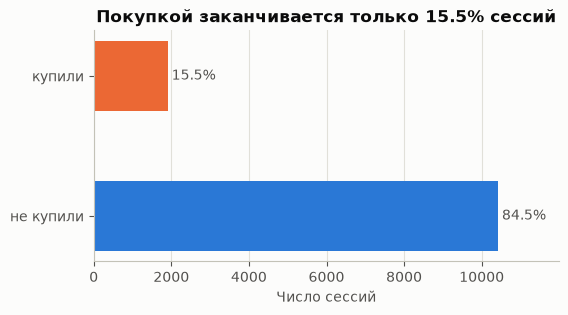

In [7]:
df = clean(raw)

class_counts = df[TARGET].value_counts().sort_index()
class_share = df[TARGET].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"сессий": class_counts, "доля": class_share.round(3)})
      .rename(index=CLASS_LABELS))

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.barh([CLASS_LABELS[i] for i in class_counts.index], class_counts.values,
               color=[CLASS_COLORS[i] for i in class_counts.index], height=0.5)
for bar, share in zip(bars, class_share.values):
    ax.text(bar.get_width() + 100, bar.get_y() + bar.get_height() / 2,
            f"{share:.1%}", va="center", color="#52514e")
ax.set_title(f"Покупкой заканчивается только {class_share[1]:.1%} сессий")
ax.set_xlabel("Число сессий")
ax.set_xlim(0, class_counts.max() * 1.15)
ax.grid(axis="y", visible=False)
save_fig(fig, "01_class_balance")
plt.show()

In [8]:
# Насколько хороша "модель", которая всегда отвечает "не купит"
always_no_accuracy = (df[TARGET] == 0).mean()
print(f'Доля верных ответов у модели "никто не купит": {always_no_accuracy:.1%}')
print(f"Сессий без покупки на одну сессию с покупкой: {class_counts[0] / class_counts[1]:.2f}")

Доля верных ответов у модели "никто не купит": 84.5%
Сессий без покупки на одну сессию с покупкой: 5.46


**Что увидел.** Покупкой заканчиваются 1908 сессий из 12 330, это 15.5%. Остальные 10 422 (84.5%) без покупки.

**Что это значит.** Классы *несбалансированы*: на одну сессию с покупкой приходится 5.46 сессии без покупки, чем визитов без покупки. Это важно для всей дальнейшей работы:

1. **Доля верных ответов (accuracy) обманчива.** Модель, которая всем говорит "не купит", права в 84.5% случаев, но магазину от неё никакой пользы: она не находит ни одного покупателя. Поэтому дальше я смотрю на метрики, которые следят именно за покупателями: precision, recall, PR-AUC (объясню в ноутбуке 05).
2. **Разбиение на train и test должно сохранять долю покупок.** Иначе в тест случайно может попасть, скажем, 12% покупок вместо 15.5%, и оценка модели будет сдвинута. Для этого есть *стратифицированное разбиение*: доля покупок в обеих частях одинаковая.
3. **Модели надо подсказать, что покупатели важны.** Без этого она научится в основном говорить "не купит". Варианты: веса классов (`class_weight`) или выбор порога, начиная с которого мы считаем "купит". Это разберу в 05.

## Очистка и разбиение на train / test

**Почему делю данные уже сейчас.** Изначально я планировал делить в ноутбуке 04, перед созданием признаков. Но тогда графики и статистические тесты в 02-03 я бы строил в том числе на тестовых данных. Идеи для признаков частично появились бы из теста, и оценка модели на нём была бы слегка завышена. Поэтому делю сразу: EDA, тесты гипотез, признаки и подбор модели делаю только на train (80%), а тест (20%) лежит нетронутым до конца ноутбука 05.

Очистка минимальная и не зависит от других строк, поэтому её можно сделать до разбиения без риска утечки: `June` → `Jun`, `Weekend` и `Revenue` → 0/1.

*Утечка (data leakage)* бывает, когда при обучении или настройке модель "подсматривает" информацию, которой у неё не будет в реальной работе. Модель тогда выглядит лучше, чем есть на самом деле.

In [9]:
train, test = make_split(df)
save_split(train, test)

split_summary = pd.DataFrame({
    "сессий": [len(train), len(test)],
    "покупок": [train[TARGET].sum(), test[TARGET].sum()],
    "доля покупок": [train[TARGET].mean().round(4), test[TARGET].mean().round(4)],
}, index=["train", "test"])
split_summary

,сессий,покупок,доля покупок
train,9864,1526,0.1547
test,2466,382,0.1549


In [10]:
# Проверка: все значения категорий из теста встречаются в train
for col in ["Month", "VisitorType", "TrafficType", "Browser", "OperatingSystems", "Region"]:
    unseen = set(test[col]) - set(train[col])
    print(f"{col}: значений в test, которых нет в train: {sorted(unseen) if unseen else 'нет'}")

Month: значений в test, которых нет в train: нет
VisitorType: значений в test, которых нет в train: нет
TrafficType: значений в test, которых нет в train: нет
Browser: значений в test, которых нет в train: нет
OperatingSystems: значений в test, которых нет в train: нет
Region: значений в test, которых нет в train: нет


**Что увидел.** В train 9864 сессии (1526 покупок), в test 2466 (382 покупки). Доля покупок в обеих частях 15.5%. Все значения категорий из теста встречаются и в train, так что модель не столкнётся в тесте с совсем незнакомым кодом.

Файлы сохранены в `data/processed/train.csv` и `data/processed/test.csv`. В них сохранён номер строки исходного файла (`row_id`), чтобы всегда можно было сверить сессию с исходными данными.

## Итоги

- В данных **12 330 сессий и 17 признаков**, пропусков нет. Покупкой заканчиваются **15.5%** сессий: классы несбалансированы, поэтому accuracy не подходит (у модели "никто не купит" она 84.5%).
- **125 точных дубликатов**, все они "пустые" визиты из одной-двух страниц без времени. Я их оставил, потому что это, скорее всего, разные люди с одинаково коротким визитом.
- **720 сессий с нулевой длительностью**: по-видимому, GA не записывает время последней страницы визита. Значит, все длительности занижены, особенно у коротких визитов.
- Данные **разделены на train (9864) и test (2466)** со стратификацией. Дальше работаю только с train.

## Что не получилось или удивило

- Неравномерность по месяцам: в феврале всего 184 сессии, января и апреля нет вообще. Почему, авторы не объясняют.
- Две покупки в "пустых" визитах (0 секунд, 1-2 страницы). Возможно, это особенность записи GA, но проверить я это не могу.

## Новые идеи

- Время последней страницы теряется, поэтому "среднее время на страницу" у коротких визитов будет сильно занижено. Это стоит учесть, когда буду придумывать признаки в 04.
- `PageValues` по определению связан с выручкой, поэтому он первый кандидат на утечку. Проверю в 04.

## Следующие шаги

- **В ноутбуке 02** сделаю разведочный анализ на train: распределения признаков, конверсия по месяцам, типам посетителей, источникам трафика и выходным, связь времени на товарных страницах с покупкой.
- **При большем времени:** найти похожий датасет с событиями корзины и ценами (например, Kaggle REES46), чтобы проверить выводы о "почти-покупателях" на настоящих корзинах.